# Fig. 7 — MDS prompt manifolds (vector PDF)

Regenerates the 7-panel *Prompt manifolds (MDS on first-token JSD distances)* figure as a
**true vector PDF**, sized to the exact text width of the single-column template so LaTeX
applies **no scaling** (scaling is what makes text look fuzzy or inconsistent between figures).

**What it needs:** the seven `*_jsd_matrix.csv` files (8x8, family-labelled) — the same ones
used for the JSD heatmaps and the Mantel panel.

**What it fixes vs. the original script** (all switchable in the config cell):
1. **Non-zero diagonals.** The saved JSD matrices have `D[i,i]` in the range 0.16–0.81
   (that entry is the mean *within-family* pairwise distance — a real quantity, but not a
   self-distance). Feeding that straight into MDS inflates normalised stress above 1, which
   is not a valid value. `DIAGONAL_MODE = "zero"` repairs it. The plotted layout is unchanged
   (Procrustes disparity ≈ 0 against the published panels), so this is a code fix, not a
   figure change.
2. **Orientation.** MDS solutions are only defined up to rotation and reflection, so a re-run
   normally comes out flipped. The notebook orthogonally aligns each panel to the published
   layout, so the new figure is recognisably the same figure.
3. **Aspect ratio.** MDS is a *distance* plot, so a unit on MDS-1 must be the same length as a
   unit on MDS-2. The original panels stretch the axes independently. `PANEL_ASPECT_EQUAL = True`.
4. **Vector output**: `pdf.fonttype = 42` (embedded TrueType, no Type-3), no `bbox_inches="tight"`
   (which silently re-crops and defeats exact sizing).

It also writes a manifest with input SHA-256 hashes, library versions, and a per-panel stress
and alignment table.

**How to run:** in Colab, leave `DATA_DIR = ""` and upload the seven files from `data/jsd_matrices/` when prompted; locally, set `DATA_DIR` to that folder.

**Note on two panels.** For DistilGPT-2 and Qwen2.5-0.5B the JSD matrices are nearly flat, so metric MDS has several near-equivalent solutions. The figure in the paper uses, for every panel, the lowest-stress solution over a seed sweep (`MDS_SEED_SWEEP`, winning seed recorded in the manifest). For those two panels this differs from the earlier rendering whose coordinates are used only for orientation, which is what the "Procrustes vs published" column in Cell 7 reports.

**Label style.** The config cell is saved with `LABEL_MODE = "index"` (numbered points with a key), the setting used for the stored preview below. The figure in the paper uses `LABEL_MODE = "full"` (family names next to the points); set that value to redraw it. The point positions are the same in both modes.

## Cell 1 — Configuration

Everything you might want to change lives here. Nothing below this cell needs editing.

In [1]:
# ============================== CONFIG ======================================

# ---- Where the input CSVs live -------------------------------------------
# Colab: mount Drive and point at the folder, or leave as "" to use the
# file-upload widget in Cell 3.
DATA_DIR = ""                 # e.g. "/content/drive/MyDrive/InformationGeometry/jsd"
MOUNT_DRIVE = False           # True -> mounts Google Drive first

# ---- Page geometry --------------------------------------------------------
# cas-sc.cls: paperwidth 192mm, hmargin 13.7mm each side
#   -> \textwidth = 192 - 13.7 - 13.7 = 164.6 mm = 6.4803 in
# If you switch to the Springer sn-jnl template, put \the\textwidth in the .tex,
# compile, read the value off the log (in pt), and divide by 72.27.
FIG_W_IN = 6.4803             # figure is drawn at EXACTLY this width
INCLUDE_WIDTH = r"\textwidth" # what you will write in \includegraphics

# ---- Panel grid -----------------------------------------------------------
NROWS, NCOLS = 2, 4           # 7 panels + 1 empty slot. Try (3, 3) if crowded.
PANEL_ASPECT_HW = 1.00        # panel height / panel width
PANEL_ASPECT_EQUAL = True     # equal data aspect (correct for a distance plot)

# ---- Labels ---------------------------------------------------------------
# "full"  -> family names next to each point (matches the original)
# "short" -> abbreviated names (fits better at 1.5 in panels)
# "index" -> numbered points + a legend in the empty grid slot (most readable)
LABEL_MODE = "index"
LABEL_OFFSET = 0.05           # label distance from its point, as a fraction of the data span

SHOW_TICKS        = False     # MDS axes carry no units; ticks are decoration
SHOW_AXIS_LABELS  = False     # "MDS 1" / "MDS 2"
SHOW_SUPTITLE     = False     # the LaTeX caption already says this
SHOW_PANEL_TITLES = True
ANNOT_STRESS      = False     # print Kruskal stress-1 in each panel corner

# ---- Method ---------------------------------------------------------------
DIAGONAL_MODE = "zero"        # "zero" = repaired (recommended) | "raw" = as-saved
SYMMETRISE    = True          # D <- (D + D.T)/2
MDS_SEED      = 42            # kept for reference; the sweep below overrides it
MDS_SEED_SWEEP = 12           # try this many starting seeds, keep the lowest-stress one
MDS_N_INIT    = 16            # restarts inside each seed
MDS_MAX_ITER  = 3000
ALIGN_TO_REFERENCE = True     # rotate/reflect each panel onto the published layout

# ---- Style ----------------------------------------------------------------
POINT_COLOR = "#2E8B8B"
POINT_EDGE  = "#111111"
POINT_SIZE  = 30
FONT_TITLE, FONT_LABEL, FONT_TICK = 8.0, 6.0, 6.0
FONT_FAMILY = "sans-serif"    # "serif" to match cas-sc body text

# ---- Layout padding, inches ----------------------------------------------
PAD_L, PAD_R, PAD_T, PAD_B = 0.03, 0.03, 0.03, 0.03
WSPACE_IN, HSPACE_IN = 0.10, 0.12
TITLE_IN = 0.15               # vertical room reserved for each panel title
AXES_MARGIN = 0.22            # fraction of data span left as blank margin

# ---- Output ---------------------------------------------------------------
OUT_PDF      = "fig_mds_manifolds.pdf"
OUT_PNG      = "fig_mds_manifolds.png"   # 600 dpi backup
OUT_MANIFEST = "fig_mds_manifolds_manifest.json"
OUT_COORDS   = "fig_mds_manifolds_coords.csv"

# ===========================================================================

## Cell 2 — Imports, environment, and PDF-safe matplotlib settings

In [2]:
import hashlib, json, os, sys, glob, warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from scipy.linalg import orthogonal_procrustes
from scipy.spatial.distance import pdist, squareform

# Vector-safe PDF output: Type-42 (TrueType) fonts, no Type-3.
matplotlib.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": FONT_FAMILY,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "figure.dpi": 110,
})

VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
}
try:
    import sklearn, scipy
    VERSIONS["scikit-learn"] = sklearn.__version__
    VERSIONS["scipy"] = scipy.__version__
except Exception:
    pass

print("Environment:")
for k, v in VERSIONS.items():
    print(f"  {k:<14} {v}")

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

Environment:
  python         3.13.15
  numpy          2.1.3
  pandas         2.2.3
  matplotlib     3.10.0
  scikit-learn   1.6.1
  scipy          1.16.3


## Cell 3 — Model / family registry

`FAMILY_ORDER` is the canonical order. `FAMILY_ALIASES` handles the `minimal` vs `base`
naming difference between exports — the A100 seven-model run labels the plain prompt family
`minimal` in some files and `base` in others, and the published figure shows `base`.

In [3]:
MODEL_ORDER = [
    "DistilGPT-2",
    "Qwen2.5-0.5B",
    "Qwen2.5-0.5B-Instruct",
    "Qwen2.5-7B",
    "Qwen2.5-7B-Instruct",
    "Llama-3.1-8B",
    "Llama-3.1-8B-Instruct",
]

# Substrings used to match a CSV filename to a model. First match wins, so the
# order matters: "-instruct" variants are tested before their base models.
MODEL_FILE_HINTS = {
    "DistilGPT-2":           ["distilgpt2", "distilgpt-2", "distil"],
    "Qwen2.5-0.5B-Instruct": ["qwen2_5_0_5b_instruct", "qwen0.5b-instruct", "qwen_small_instruct",
                              "qwen2.5-0.5b-instruct", "0_5b_instruct", "0.5b-instruct"],
    "Qwen2.5-0.5B":          ["qwen2_5_0_5b", "qwen_small", "qwen2.5-0.5b", "0_5b", "0.5b"],
    "Qwen2.5-7B-Instruct":   ["qwen2_5_7b_instruct", "qwen2.5-7b-instruct", "7b_instruct", "7b-instruct"],
    "Qwen2.5-7B":            ["qwen2_5_7b", "qwen2.5-7b", "qwen_7b", "7b"],
    "Llama-3.1-8B-Instruct": ["llama_3_1_8b_instruct", "llama3.1-8b-instruct", "llama_8b_instruct",
                              "8b_instruct", "8b-instruct"],
    "Llama-3.1-8B":          ["llama_3_1_8b", "llama3.1-8b", "llama_8b", "llama"],
}
# Matching is attempted in this order (most specific first):
HINT_ORDER = ["DistilGPT-2", "Qwen2.5-0.5B-Instruct", "Qwen2.5-7B-Instruct",
              "Llama-3.1-8B-Instruct", "Qwen2.5-0.5B", "Qwen2.5-7B", "Llama-3.1-8B"]

FAMILY_ORDER = ["base", "expert", "cot", "structured", "concise",
                "overconstrained", "robust", "formatting"]

FAMILY_ALIASES = {
    "minimal": "base", "plain": "base", "baseline": "base",
    "chain_of_thought": "cot", "chain-of-thought": "cot",
    "over_constrained": "overconstrained", "over-constrained": "overconstrained",
    "format": "formatting", "struct": "structured",
}

SHORT_NAMES = {
    "base": "base", "expert": "expert", "cot": "cot", "structured": "struct.",
    "concise": "concise", "overconstrained": "overcon.", "robust": "robust",
    "formatting": "format.",
}

def canon_family(name: str) -> str:
    k = str(name).strip().lower().replace(" ", "_")
    return FAMILY_ALIASES.get(k, k)

print("Families:", FAMILY_ORDER)

Families: ['base', 'expert', 'cot', 'structured', 'concise', 'overconstrained', 'robust', 'formatting']


## Cell 4 — Load the seven JSD matrices

Point `DATA_DIR` at the folder, or run this cell with `DATA_DIR = ""` in Colab and use the
upload widget. Each file must be an 8x8 matrix with family names as the index and columns.

In [4]:
MODEL_FILES = {
    "DistilGPT-2":           "distilgpt2_jsd_matrix.csv",
    "Qwen2.5-0.5B":          "qwen2_5_0_5b_jsd_matrix.csv",
    "Qwen2.5-0.5B-Instruct": "qwen2_5_0_5b_instruct_jsd_matrix.csv",
    "Qwen2.5-7B":            "qwen2_5_7b_jsd_matrix.csv",
    "Qwen2.5-7B-Instruct":   "qwen2_5_7b_instruct_jsd_matrix.csv",
    "Llama-3.1-8B":          "llama_3_1_8b_jsd_matrix.csv",
    "Llama-3.1-8B-Instruct": "llama_3_1_8b_instruct_jsd_matrix.csv",
}

# Fallback matching if a file has been renamed. Most specific hints first, so
# the "-instruct" variants are never swallowed by their base model's hint.
HINT_ORDER = ["DistilGPT-2", "Qwen2.5-0.5B-Instruct", "Qwen2.5-7B-Instruct",
              "Llama-3.1-8B-Instruct", "Qwen2.5-0.5B", "Qwen2.5-7B", "Llama-3.1-8B"]
MODEL_FILE_HINTS = {
    "DistilGPT-2":           ["distilgpt2", "distilgpt-2", "distil"],
    "Qwen2.5-0.5B-Instruct": ["0_5b_instruct", "0.5b-instruct", "qwen_small_instruct"],
    "Qwen2.5-7B-Instruct":   ["7b_instruct", "7b-instruct"],
    "Llama-3.1-8B-Instruct": ["8b_instruct", "8b-instruct"],
    "Qwen2.5-0.5B":          ["0_5b", "0.5b", "qwen_small"],
    "Qwen2.5-7B":            ["qwen2_5_7b", "qwen2.5-7b", "qwen_7b"],
    "Llama-3.1-8B":          ["llama_3_1_8b", "llama3.1-8b", "llama"],
}


def _read_matrix(path):
    df = pd.read_csv(path, index_col=0)
    if df.shape[0] != df.shape[1]:                       # unnamed label column
        df = pd.read_csv(path)
        df = df.set_index(df.columns[0])
    df.index = [canon_family(i) for i in df.index]
    df.columns = [canon_family(c) for c in df.columns]

    if df.index.has_duplicates or df.columns.has_duplicates:
        raise ValueError(f"{os.path.basename(path)}: duplicate row or column labels")
    missing = [f for f in FAMILY_ORDER if f not in df.index or f not in df.columns]
    if missing:
        raise ValueError(f"{os.path.basename(path)}: missing families {missing}; "
                         f"found {list(df.index)}")

    df = df.loc[FAMILY_ORDER, FAMILY_ORDER].astype(float)
    v = df.to_numpy()
    if not np.isfinite(v).all():
        raise ValueError(f"{os.path.basename(path)}: contains NaN or inf")
    if v.min() < 0 or v.max() > 1:
        raise ValueError(f"{os.path.basename(path)}: JSD values must lie in [0, 1]")
    return df


def _sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _fuzzy(filename):
    low = os.path.basename(filename).lower()
    for model in HINT_ORDER:
        if any(hint in low for hint in MODEL_FILE_HINTS[model]):
            return model
    return None


def _collect_paths():
    if DATA_DIR:
        available = {os.path.basename(p): p
                     for p in glob.glob(os.path.join(os.path.expanduser(DATA_DIR), "*.csv"))}
    else:
        try:
            from google.colab import files
            print("Upload all seven JSD matrix CSV files together:")
            uploaded = files.upload()
            available = {os.path.basename(n): n for n in uploaded}
        except ImportError:
            available = {os.path.basename(p): p for p in glob.glob("*.csv")}

    resolved, how = {}, {}
    for model, wanted in MODEL_FILES.items():           # exact name wins
        if wanted in available:
            resolved[model] = available[wanted]
            how[model] = "exact"
    for name, path in available.items():                # then fuzzy for the rest
        model = _fuzzy(name)
        if model and model not in resolved:
            resolved[model] = path
            how[model] = "matched by name"

    missing = [m for m in MODEL_ORDER if m not in resolved]
    if missing:
        raise FileNotFoundError(
            "No CSV found for: " + ", ".join(missing) +
            "\nExpected filenames:\n  - " + "\n  - ".join(MODEL_FILES[m] for m in missing) +
            "\nUpload all seven together, or set DATA_DIR to their folder."
        )
    return resolved, how


CSV_PATHS, MATCH_HOW = _collect_paths()
MATRICES, INPUT_FILES = {}, {}
for model in MODEL_ORDER:
    p = CSV_PATHS[model]
    MATRICES[model] = _read_matrix(p)
    INPUT_FILES[model] = {"file": os.path.basename(p), "sha256": _sha256(p)}
    print(f"  {model:<24} <- {os.path.basename(p):<40} ({MATCH_HOW[model]})")

print(f"\nLoaded {len(MATRICES)}/7 matrices from CSV. No values are hard-coded anywhere.")

Upload all seven JSD matrix CSV files together:


Saving distilgpt2_jsd_matrix.csv to distilgpt2_jsd_matrix.csv
Saving llama_3_1_8b_instruct_jsd_matrix.csv to llama_3_1_8b_instruct_jsd_matrix.csv
Saving llama_3_1_8b_jsd_matrix.csv to llama_3_1_8b_jsd_matrix.csv
Saving qwen2_5_0_5b_instruct_jsd_matrix.csv to qwen2_5_0_5b_instruct_jsd_matrix.csv
Saving qwen2_5_0_5b_jsd_matrix.csv to qwen2_5_0_5b_jsd_matrix.csv
Saving qwen2_5_7b_instruct_jsd_matrix.csv to qwen2_5_7b_instruct_jsd_matrix.csv
Saving qwen2_5_7b_jsd_matrix.csv to qwen2_5_7b_jsd_matrix.csv
  DistilGPT-2              <- distilgpt2_jsd_matrix.csv                (exact)
  Qwen2.5-0.5B             <- qwen2_5_0_5b_jsd_matrix.csv              (exact)
  Qwen2.5-0.5B-Instruct    <- qwen2_5_0_5b_instruct_jsd_matrix.csv     (exact)
  Qwen2.5-7B               <- qwen2_5_7b_jsd_matrix.csv                (exact)
  Qwen2.5-7B-Instruct      <- qwen2_5_7b_instruct_jsd_matrix.csv       (exact)
  Llama-3.1-8B             <- llama_3_1_8b_jsd_matrix.csv              (exact)
  Llama-3.1-8B-Instruc

## Cell 5 — Inspect and repair the matrices

This prints exactly what is being changed, so the repair is auditable rather than silent.

In [5]:
REPAIR_LOG = []

def repair(D_df, label):
    D = D_df.to_numpy(dtype=float).copy()
    diag = np.diag(D).copy()
    asym = float(np.abs(D - D.T).max())

    if SYMMETRISE:
        D = 0.5 * (D + D.T)
    if DIAGONAL_MODE == "zero":
        np.fill_diagonal(D, 0.0)

    neg = int((D < 0).sum())
    if neg:
        warnings.warn(f"{label}: {neg} negative entries clipped to 0")
        D = np.clip(D, 0.0, None)

    REPAIR_LOG.append({
        "model": label,
        "diag_min": float(diag.min()), "diag_max": float(diag.max()),
        "max_asymmetry": asym,
        "offdiag_mean": float(D[~np.eye(8, dtype=bool)].mean()),
    })
    return D

D_REPAIRED = {m: repair(MATRICES[m], m) for m in MODEL_ORDER}
rep = pd.DataFrame(REPAIR_LOG).set_index("model").round(4)
print(f"DIAGONAL_MODE = {DIAGONAL_MODE!r}, SYMMETRISE = {SYMMETRISE}\n")
print(rep.to_string())
print("\n'diag_min/max' are the values found in the saved files BEFORE repair.")
print("'offdiag_mean' is the average inter-family JSD distance and should match")
print("the seven values reported in the paper: 0.10 / 0.27 / 0.42 / 0.36 / 0.57 / 0.22 / 0.49")

DIAGONAL_MODE = 'zero', SYMMETRISE = True

                       diag_min  diag_max  max_asymmetry  offdiag_mean
model                                                                 
DistilGPT-2               0.507     0.544            0.0        0.0966
Qwen2.5-0.5B              0.543     0.678            0.0        0.2702
Qwen2.5-0.5B-Instruct     0.519     0.773            0.0        0.4156
Qwen2.5-7B                0.501     0.716            0.0        0.3617
Qwen2.5-7B-Instruct       0.159     0.811            0.0        0.5686
Llama-3.1-8B              0.593     0.688            0.0        0.2169
Llama-3.1-8B-Instruct     0.283     0.779            0.0        0.4931

'diag_min/max' are the values found in the saved files BEFORE repair.
'offdiag_mean' is the average inter-family JSD distance and should match
the seven values reported in the paper: 0.10 / 0.27 / 0.42 / 0.36 / 0.57 / 0.22 / 0.49


## Cell 6 — Reference layout (orientation only)

These coordinates are read off an earlier raster rendering of this figure. **They are never plotted as data.** They are
used only to decide how to rotate and reflect each freshly-computed MDS solution, because MDS
fixes a configuration only up to a rigid motion. Turning `ALIGN_TO_REFERENCE` off gives a
mathematically identical figure in a different orientation.

In [6]:
REFERENCE_COORDS = {
 "DistilGPT-2": {
   "robust": (-0.018, 0.072), "expert": (0.035, 0.058), "concise": (-0.045, 0.023),
   "overconstrained": (-0.007, 0.017), "cot": (0.040, 0.003), "formatting": (-0.065, -0.047),
   "base": (-0.007, -0.046), "structured": (0.058, -0.084)},
 "Qwen2.5-0.5B": {
   "concise": (0.096, 0.207), "base": (-0.148, 0.155), "formatting": (0.147, 0.083),
   "expert": (-0.062, 0.013), "robust": (0.028, -0.081), "overconstrained": (0.122, -0.068),
   "structured": (-0.190, -0.081), "cot": (0.002, -0.230)},
 "Qwen2.5-0.5B-Instruct": {
   "cot": (0.155, 0.345), "structured": (-0.185, 0.298), "robust": (0.205, 0.153),
   "base": (0.110, -0.062), "expert": (0.200, -0.126), "overconstrained": (-0.262, -0.120),
   "concise": (-0.185, -0.222), "formatting": (-0.052, -0.262)},
 "Qwen2.5-7B": {
   "base": (0.262, 0.240), "overconstrained": (-0.092, 0.240), "concise": (-0.035, 0.122),
   "formatting": (-0.228, 0.060), "expert": (0.130, -0.037), "robust": (0.028, -0.167),
   "structured": (-0.175, -0.218), "cot": (0.108, -0.242)},
 "Qwen2.5-7B-Instruct": {
   "structured": (-0.335, 0.568), "cot": (0.245, 0.373), "robust": (0.330, 0.005),
   "overconstrained": (-0.340, -0.118), "concise": (-0.200, -0.178), "base": (0.212, -0.157),
   "expert": (0.258, -0.192), "formatting": (-0.192, -0.302)},
 "Llama-3.1-8B": {
   "structured": (-0.037, 0.203), "cot": (0.088, 0.103), "robust": (-0.072, 0.037),
   "base": (0.143, -0.003), "expert": (0.010, -0.008), "concise": (0.090, -0.072),
   "overconstrained": (-0.170, -0.090), "formatting": (-0.052, -0.168)},
 "Llama-3.1-8B-Instruct": {
   "structured": (-0.208, 0.607), "cot": (0.355, 0.253), "robust": (0.178, -0.043),
   "formatting": (-0.062, -0.057), "overconstrained": (-0.325, -0.130), "base": (0.098, -0.172),
   "expert": (0.170, -0.183), "concise": (-0.218, -0.278)},
}

REF = {m: np.array([REFERENCE_COORDS[m][f] for f in FAMILY_ORDER], dtype=float)
       for m in MODEL_ORDER}
print("Reference layouts loaded for", len(REF), "models (orientation only).")

Reference layouts loaded for 7 models (orientation only).


## Cell 7 — Embed and align

Stress-1 is computed by hand rather than read off `MDS.stress_`, because the meaning of that
attribute has changed between scikit-learn versions. Stress-1 = sqrt( Σ(d − d̂)² / Σ d² ) over
the strict upper triangle; below about 0.10 is generally read as a good two-dimensional fit.

In [7]:
def stress1(D, X):
    dhat = pdist(X)
    d = squareform(D, checks=False)
    denom = np.sum(d ** 2)
    return float(np.sqrt(np.sum((d - dhat) ** 2) / denom)) if denom > 0 else np.nan

# scikit-learn renamed the precomputed-distance switch: `dissimilarity="precomputed"`
# is deprecated in 1.8 and removed in 1.10 in favour of `metric="precomputed"`.
# Pick whichever the installed version actually has.
import inspect
_MDS_PARAMS = inspect.signature(MDS.__init__).parameters
_PRECOMPUTED = ({"dissimilarity": "precomputed"} if "dissimilarity" in _MDS_PARAMS
                else {"metric": "precomputed"})

def embed(D, seed=MDS_SEED):
    kw = dict(n_components=2, random_state=seed, n_init=MDS_N_INIT,
              max_iter=MDS_MAX_ITER, eps=1e-9, **_PRECOMPUTED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        return MDS(**kw).fit_transform(D)

def align(X, ref):
    """Rotate/reflect X onto ref. Scale and shape are untouched."""
    Xc = X - X.mean(0)
    Rc = ref - ref.mean(0)
    Rc = Rc / (np.linalg.norm(Rc) or 1.0) * (np.linalg.norm(Xc) or 1.0)
    R, _ = orthogonal_procrustes(Xc, Rc)
    return Xc @ R

def disparity(X, ref):
    """Scale-free residual after optimal rotation: 0 = same layout."""
    A = X - X.mean(0); B = ref - ref.mean(0)
    A = A / (np.linalg.norm(A) or 1.0); B = B / (np.linalg.norm(B) or 1.0)
    R, _ = orthogonal_procrustes(A, B)
    return float(np.sum((A @ R - B) ** 2))

def best_embedding(D, n_seeds=MDS_SEED_SWEEP):
    """Run the search from several starting seeds and keep the lowest-stress result.

    SMACOF descends from a random start, so a single run can settle in a local
    minimum that is not the best arrangement the data allows. `n_init` already
    guards against this, but not completely: on a nearly-flat distance matrix
    (DistilGPT-2, Qwen2.5-0.5B) even n_init=16 lands in a worse dip for some
    seeds. Sweeping seeds and keeping the winner removes that luck entirely.
    """
    runs = [(stress1(D, X), seed, X)
            for seed, X in ((s, embed(D, seed=s)) for s in range(n_seeds))]
    runs.sort(key=lambda r: r[0])
    best_stress, best_seed, best_X = runs[0]
    return best_X, best_stress, best_seed, runs[-1][0]

EMB, STRESS, DISP, WINNING_SEED, WORST_STRESS = {}, {}, {}, {}, {}
for m in MODEL_ORDER:
    D = D_REPAIRED[m]
    X, best_stress, best_seed, worst_stress = best_embedding(D)
    STRESS[m] = best_stress
    WINNING_SEED[m] = best_seed
    WORST_STRESS[m] = worst_stress
    Draw = MATRICES[m].to_numpy(float)                 # for the record only
    STRESS[m + " (raw diag)"] = stress1(0.5 * (Draw + Draw.T), X)
    DISP[m] = disparity(X, REF[m])
    EMB[m] = align(X, REF[m]) if ALIGN_TO_REFERENCE else X

summary = pd.DataFrame({
    "stress1 (kept)": {m: STRESS[m] for m in MODEL_ORDER},
    "stress1 (worst seed)": WORST_STRESS,
    "seed kept": WINNING_SEED,
    "Procrustes vs published": DISP,
}).round(4)
print(summary.to_string())
print()
print(f"Each panel is the best of {MDS_SEED_SWEEP} seeds x n_init={MDS_N_INIT}; the winning")
print("seed is recorded in the manifest so this is exactly reproducible.")
print()
print("'Procrustes vs published': ~0 means this panel is the same arrangement as the")
print("published figure (possibly rotated, which is meaningless in MDS). A value above")
print("~0.05 means the arrangement genuinely differs. Expect that for DistilGPT-2 and")
print("Qwen2.5-0.5B: the published panels for those two were suboptimal local minima,")
print("and the layouts kept here have lower stress. Any sentence in the manuscript that")
print("describes WHICH families sit near each other in those two panels must be re-read")
print("against the new figure.")

                       stress1 (kept)  stress1 (worst seed)  seed kept  Procrustes vs published
DistilGPT-2                    0.1861                0.1862          8                   0.4403
Qwen2.5-0.5B                   0.1901                0.2181          0                   0.2006
Qwen2.5-0.5B-Instruct          0.1376                0.1376          1                   0.0001
Qwen2.5-7B                     0.1882                0.1886          1                   0.1190
Qwen2.5-7B-Instruct            0.1446                0.1446          6                   0.0002
Llama-3.1-8B                   0.1521                0.1521         11                   0.0002
Llama-3.1-8B-Instruct          0.1130                0.1130          7                   0.0003

Each panel is the best of 12 seeds x n_init=16; the winning
seed is recorded in the manifest so this is exactly reproducible.

'Procrustes vs published': ~0 means this panel is the same arrangement as the
published figure (possibly

## Cell 7b — Solution stability (read this before trusting a panel)

SMACOF, the algorithm behind metric MDS, minimises stress by gradient descent from a random
start, so it can settle into a local minimum. Panels whose distance matrix is nearly flat —
every family roughly equidistant — have many near-equivalent 2-D arrangements, and which one
you get depends on the seed and on `n_init`. This cell re-runs each panel from several seeds
and reports how much the answer moves. Anything with a non-zero spread here should not be
interpreted point-by-point in the text.

In [8]:
STABILITY_SEEDS = MDS_SEED_SWEEP   # same sweep Cell 7 used, re-examined

def _shape_disparity(A, B):
    """Scale-free residual after the best rotation/reflection. 0 = same shape."""
    A = A - A.mean(0); B = B - B.mean(0)
    A = A / (np.linalg.norm(A) or 1.0); B = B / (np.linalg.norm(B) or 1.0)
    R, _ = orthogonal_procrustes(A, B)
    return float(np.sum((A @ R - B) ** 2))


stab_rows = []
for model in MODEL_ORDER:
    D = D_REPAIRED[model]
    runs = [embed(D, seed=s) for s in range(STABILITY_SEEDS)]
    stresses = [stress1(D, X) for X in runs]
    best = runs[int(np.argmin(stresses))]          # same rule Cell 7 used
    spread = [_shape_disparity(best, X) for X in runs]
    offdiag = D[~np.eye(8, dtype=bool)]
    stab_rows.append({
        "model": model,
        "stress1": min(stresses),
        "stress1 worst restart": max(stresses),
        "shape spread": max(spread),
        "distance contrast": float(offdiag.max() - offdiag.min()),
    })

stab = pd.DataFrame(stab_rows).set_index("model").round(4)
print(stab.to_string())
print()
print("stress1              : Kruskal stress-1 of the solution kept. Rule of thumb -")
print("                       <0.05 excellent, ~0.10 fair, >0.20 poor. High stress means")
print("                       the 2-D picture is a lossy summary of the 8x8 distances.")
print("'stress1 worst restart' above 'stress1' means at least one seed got stuck in a")
print("worse local minimum. Cell 7 keeps the lowest-stress one, so a gap here is not a")
print("problem - it is the reason the sweep exists.")
print("'shape spread' > 0 means restarts disagree about the ARRANGEMENT, not just its")
print("                       orientation - those panels are not safe to read point-by-point.")
print("'distance contrast'  : max minus min off-diagonal distance. When this is small the")
print("                       families are nearly equidistant and the layout is barely")
print("                       determined by the data at all.")

                       stress1  stress1 worst restart  shape spread  distance contrast
model                                                                                 
DistilGPT-2             0.1861                 0.1862        0.0005              0.078
Qwen2.5-0.5B            0.1901                 0.2181        0.4620              0.211
Qwen2.5-0.5B-Instruct   0.1376                 0.1376        0.0000              0.445
Qwen2.5-7B              0.1882                 0.1886        0.1123              0.356
Qwen2.5-7B-Instruct     0.1446                 0.1446        0.0000              0.716
Llama-3.1-8B            0.1521                 0.1521        0.0000              0.202
Llama-3.1-8B-Instruct   0.1130                 0.1130        0.0000              0.696

stress1              : Kruskal stress-1 of the solution kept. Rule of thumb -
                       <0.05 excellent, ~0.10 fair, >0.20 poor. High stress means
                       the 2-D picture is a lossy summar

## Cell 8 — Draw the figure

The canvas is built outward from an exact `FIG_W_IN`, with axes placed by explicit fractions
rather than `tight_layout`, so the saved PDF is exactly the width LaTeX expects.

LABEL_MODE='index' -> POINT_SIZE raised to 55
Canvas:      6.4803 x 3.5401 in  = 164.6 x 89.9 mm  ->  no scaling at \textwidth
Panel width: 1.53 in   Label mode: 'index'

Labels are auto-fitted inside their panel, so a long name such as
'overconstrained' shrinks the plotted cloud instead of being clipped.
If the clouds look too small, set LABEL_MODE='short' or 'index',
or use NROWS, NCOLS = 3, 3 for bigger panels.


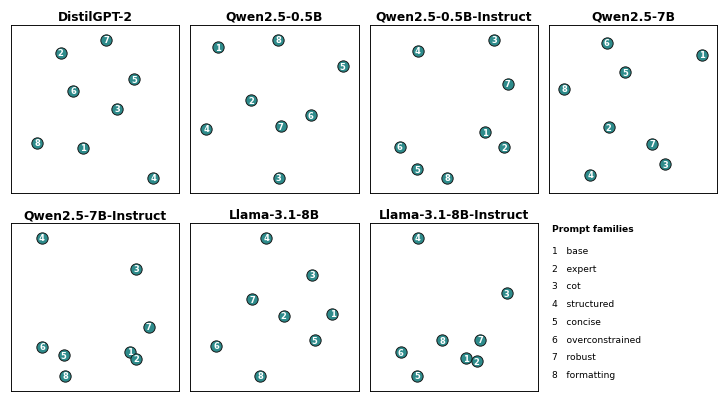

In [9]:
def label_offsets(X):
    """Pick, for each point, the compass direction that is least crowded."""
    span = float(max(np.ptp(X[:, 0]), np.ptp(X[:, 1]))) or 1.0
    dirs = [(1, 0), (0.75, 0.75), (0, 1), (-0.75, 0.75),
            (-1, 0), (-0.75, -0.75), (0, -1), (0.75, -0.75)]
    centroid = X.mean(0)
    out = []
    for i, p in enumerate(X):
        others = np.delete(X, i, axis=0)
        best, best_score = dirs[0], np.inf
        for d in dirs:
            probe = p + np.array(d) * span * 0.15
            # penalise directions that land near another point ...
            crowd = float(np.sum(np.exp(-np.linalg.norm(others - probe, axis=1) / (span * 0.15))))
            # ... and directions pointing back into the middle of the cloud
            crowd += 0.6 * float(np.exp(-np.linalg.norm(centroid - probe) / (span * 0.45)))
            if crowd < best_score:
                best, best_score = d, crowd
        out.append(best)
    return out



def _boxes(fig, texts):
    rend = fig.canvas.get_renderer()
    return [t.get_window_extent(renderer=rend) for t in texts]


def _overlap(a, b):
    w = min(a.x1, b.x1) - max(a.x0, b.x0)
    h = min(a.y1, b.y1) - max(a.y0, b.y0)
    return w * h if (w > 0 and h > 0) else 0.0


def place_labels(fig, ax, X, texts, rounds=2):
    """Nudge each label until it stops sitting on another label or on a marker.

    label_offsets() only knows where the POINTS are, so two labels could still be
    thrown into the same gap - that is what produced 'structuredrobust' and
    'baseexpert'. This pass measures the rendered text boxes and moves each label
    to the least-colliding of 16 candidate spots around its own point.
    """
    if not texts:
        return
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    pts_disp = ax.transData.transform(X)
    span = float(max(np.ptp(X[:, 0]), np.ptp(X[:, 1]))) or 1.0
    dirs = [(1, 0), (0.75, 0.75), (0, 1), (-0.75, 0.75),
            (-1, 0), (-0.75, -0.75), (0, -1), (0.75, -0.75)]

    for _ in range(rounds):
        for i, t in enumerate(texts):
            px, py = X[i]
            others = [texts[j].get_window_extent(renderer=rend)
                      for j in range(len(texts)) if j != i]
            best, best_score = None, np.inf
            for dx, dy in dirs:
                for reach in (LABEL_OFFSET, LABEL_OFFSET * 1.9):
                    ha = "left" if dx > 0.2 else ("right" if dx < -0.2 else "center")
                    va = "bottom" if dy > 0.2 else ("top" if dy < -0.2 else "center")
                    t.set_position((px + dx * span * reach, py + dy * span * reach))
                    t.set_ha(ha); t.set_va(va)
                    bb = t.get_window_extent(renderer=rend)

                    score = sum(_overlap(bb, o) for o in others)          # label vs label
                    for k, (mx, my) in enumerate(pts_disp):               # label vs marker
                        if bb.x0 - 3 < mx < bb.x1 + 3 and bb.y0 - 3 < my < bb.y1 + 3:
                            score += 400.0 if k != i else 120.0
                    score += 25.0 * (reach / LABEL_OFFSET - 1.0)          # prefer close labels
                    if score < best_score:
                        best_score, best = score, (t.get_position(), ha, va)
            t.set_position(best[0]); t.set_ha(best[1]); t.set_va(best[2])


def fit_limits(fig, ax, X, texts, equal=True, pad=0.06, iters=6, reset=True):
    """Grow the axes until every point AND every label sits inside it.

    Labels are anchored in data coordinates but sized in typographic points, so
    this has to iterate: changing the limits changes how much data-space a label
    occupies. Three passes is plenty for convergence.
    """
    if reset:
        # Start from the point cloud each time. Without this the grow-only rule
        # below would accumulate across successive calls and leave the cloud
        # marooned in the middle of a mostly empty panel.
        cx = float(X[:, 0].min() + X[:, 0].max()) / 2
        cy = float(X[:, 1].min() + X[:, 1].max()) / 2
        h0 = float(max(np.ptp(X[:, 0]), np.ptp(X[:, 1]))) / 2 * (1 + AXES_MARGIN)
        ax.set_xlim(cx - h0, cx + h0)
        ax.set_ylim(cy - h0, cy + h0)

    for _ in range(iters):
        fig.canvas.draw()
        rend = fig.canvas.get_renderer()
        xs = [float(X[:, 0].min()), float(X[:, 0].max())]
        ys = [float(X[:, 1].min()), float(X[:, 1].max())]
        for t in texts:
            bb = t.get_window_extent(renderer=rend).transformed(ax.transData.inverted())
            xs += [bb.x0, bb.x1]
            ys += [bb.y0, bb.y1]
        x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
        dx, dy = (x1 - x0) * pad, (y1 - y0) * pad
        x0, x1, y0, y1 = x0 - dx, x1 + dx, y0 - dy, y1 + dy
        if equal:
            cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
            h = max(x1 - x0, y1 - y0) / 2
            new = (cx - h, cx + h, cy - h, cy + h)
        else:
            new = (x0, x1, y0, y1)
        # Only ever grow. Locking the aspect resizes the axes box, which changes
        # how much data-space a label occupies, so a shrinking step can leave a
        # label hanging outside on the next pass - which is what clipped
        # 'overconstrained' in the earlier render.
        cur = (*ax.get_xlim(), *ax.get_ylim())
        ax.set_xlim(min(new[0], cur[0]), max(new[1], cur[1]))
        ax.set_ylim(min(new[2], cur[2]), max(new[3], cur[3]))
        if equal:                      # re-square after the union
            (a, b), (c, d) = ax.get_xlim(), ax.get_ylim()
            cx, cy = (a + b) / 2, (c + d) / 2
            h = max(b - a, d - c) / 2
            ax.set_xlim(cx - h, cx + h)
            ax.set_ylim(cy - h, cy + h)


def draw():
    global POINT_SIZE
    if LABEL_MODE == "index" and POINT_SIZE < 50:
        POINT_SIZE = 55          # numbers need a bigger marker to sit inside
        print(f"LABEL_MODE='index' -> POINT_SIZE raised to {POINT_SIZE}")
    panel_w = (FIG_W_IN - PAD_L - PAD_R - (NCOLS - 1) * WSPACE_IN) / NCOLS
    panel_h = panel_w * PANEL_ASPECT_HW
    row_h = panel_h + (TITLE_IN if SHOW_PANEL_TITLES else 0.0)
    fig_h = PAD_T + NROWS * row_h + (NROWS - 1) * HSPACE_IN + PAD_B
    if SHOW_SUPTITLE:
        fig_h += 0.22

    fig = plt.figure(figsize=(FIG_W_IN, fig_h))
    axes = []
    for idx in range(NROWS * NCOLS):
        r, c = divmod(idx, NCOLS)
        left = (PAD_L + c * (panel_w + WSPACE_IN)) / FIG_W_IN
        top_off = PAD_T + r * (row_h + HSPACE_IN) + (TITLE_IN if SHOW_PANEL_TITLES else 0.0)
        bottom = 1.0 - (top_off + panel_h) / fig_h
        axes.append(fig.add_axes([left, bottom, panel_w / FIG_W_IN, panel_h / fig_h]))

    for i, model in enumerate(MODEL_ORDER):
        ax, X = axes[i], EMB[model]
        ax.scatter(X[:, 0], X[:, 1], s=POINT_SIZE, c=POINT_COLOR,
                   edgecolors=POINT_EDGE, linewidths=0.6, zorder=3)

        # Provisional limits centred on the MID-RANGE, not the mean: with the
        # aspect locked, centring on the mean can push an outlying point (e.g.
        # 'structured' in the instruct panels) outside the box.
        cx = float(X[:, 0].min() + X[:, 0].max()) / 2
        cy = float(X[:, 1].min() + X[:, 1].max()) / 2
        half = float(max(np.ptp(X[:, 0]), np.ptp(X[:, 1]))) / 2 * (1 + AXES_MARGIN)
        ax.set_xlim(cx - half, cx + half)
        ax.set_ylim(cy - half, cy + half)
        if PANEL_ASPECT_EQUAL:
            ax.set_aspect("equal", adjustable="box")

        texts = []
        if LABEL_MODE != "index":
            span = float(max(np.ptp(X[:, 0]), np.ptp(X[:, 1]))) or 1.0
            for (px, py), (dx, dy), fam in zip(X, label_offsets(X), FAMILY_ORDER):
                label = fam if LABEL_MODE == "full" else SHORT_NAMES[fam]
                ha = "left" if dx > 0.2 else ("right" if dx < -0.2 else "center")
                va = "bottom" if dy > 0.2 else ("top" if dy < -0.2 else "center")
                texts.append(ax.text(px + dx * span * LABEL_OFFSET,
                                     py + dy * span * LABEL_OFFSET,
                                     label, fontsize=FONT_LABEL, ha=ha, va=va, zorder=4))
        else:
            for n, (px, py) in enumerate(X, start=1):
                ax.text(px, py, str(n), fontsize=FONT_LABEL - 0.5, ha="center", va="center",
                        color="white", zorder=5, fontweight="bold")

        # Fit once so labels are measured at roughly the final scale, then
        # de-collide them, then re-fit in case a moved label now sticks out.
        fit_limits(fig, ax, X, texts, equal=PANEL_ASPECT_EQUAL)
        place_labels(fig, ax, X, texts)
        fit_limits(fig, ax, X, texts, equal=PANEL_ASPECT_EQUAL, iters=3)
        place_labels(fig, ax, X, texts, rounds=1)
        # slightly larger pad on the final pass: measured text extents sit a
        # hair inside the rendered glyphs, which was letting one stroke of
        # "overconstrained" bleed off the canvas edge.
        fit_limits(fig, ax, X, texts, equal=PANEL_ASPECT_EQUAL, iters=2, pad=0.10)

        if SHOW_PANEL_TITLES:
            ax.set_title(model, fontsize=FONT_TITLE, pad=3.0, fontweight="bold")
        if SHOW_TICKS:
            ax.tick_params(labelsize=FONT_TICK, length=2, pad=1.5)
        else:
            ax.set_xticks([])
            ax.set_yticks([])
        if SHOW_AXIS_LABELS:
            ax.set_xlabel("MDS 1", fontsize=FONT_LABEL, labelpad=1.5)
            ax.set_ylabel("MDS 2", fontsize=FONT_LABEL, labelpad=1.5)
        if ANNOT_STRESS and np.isfinite(STRESS.get(model, np.nan)):
            ax.text(0.03, 0.03, f"stress-1 = {STRESS[model]:.3f}", transform=ax.transAxes,
                    fontsize=FONT_LABEL - 0.5, alpha=0.75, ha="left", va="bottom")

    # Unused grid slots: left blank, or used for the numbered-family key.
    for ax in axes[len(MODEL_ORDER):]:
        ax.axis("off")
        if LABEL_MODE == "index":
            ax.text(0.02, 0.99, "Prompt families", fontsize=FONT_LABEL,
                    fontweight="bold", transform=ax.transAxes, va="top")
            for n, fam in enumerate(FAMILY_ORDER, start=1):
                ax.text(0.02, 0.86 - 0.105 * (n - 1), f"{n}   {fam}",
                        fontsize=FONT_LABEL, transform=ax.transAxes, va="top")

    if SHOW_SUPTITLE:
        fig.suptitle("Prompt manifolds (MDS on first-token JSD distances)",
                     fontsize=FONT_TITLE + 1, fontweight="bold", y=0.995)
    return fig, fig_h


fig, FIG_H_IN = draw()
_pw = (FIG_W_IN - PAD_L - PAD_R - (NCOLS - 1) * WSPACE_IN) / NCOLS
print(f"Canvas:      {FIG_W_IN:.4f} x {FIG_H_IN:.4f} in  "
      f"= {FIG_W_IN*25.4:.1f} x {FIG_H_IN*25.4:.1f} mm  ->  no scaling at {INCLUDE_WIDTH}")
print(f"Panel width: {_pw:.2f} in   Label mode: {LABEL_MODE!r}")
print()
print("Labels are auto-fitted inside their panel, so a long name such as")
print("'overconstrained' shrinks the plotted cloud instead of being clipped.")
print("If the clouds look too small, set LABEL_MODE='short' or 'index',")
print("or use NROWS, NCOLS = 3, 3 for bigger panels.")
fig

## Cell 9 — Save the PDF (and a PNG backup + manifest)

`bbox_inches="tight"` is deliberately **not** used: it re-crops the canvas and would undo the
exact sizing.

In [10]:
fig.savefig(OUT_PDF, format="pdf")                      # vector, exact size
fig.savefig(OUT_PNG, format="png", dpi=600)             # raster backup
plt.close(fig)

rows = []
for m in MODEL_ORDER:
    for f, (x, y) in zip(FAMILY_ORDER, EMB[m]):
        rows.append({"model": m, "family": f, "mds1": x, "mds2": y})
pd.DataFrame(rows).to_csv(OUT_COORDS, index=False)

manifest = {
    "figure": "MDS prompt manifolds (first-token JSD)",
    "generated_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "data_source": "uploaded CSV matrices only",
    "canvas_in": [FIG_W_IN, FIG_H_IN],
    "target_textwidth_note": "cas-sc.cls: 192mm paper - 2*13.7mm hmargin = 164.6mm = 6.4803in",
    "method": {
        "diagonal_mode": DIAGONAL_MODE, "symmetrise": SYMMETRISE,
        "mds_seed_sweep": MDS_SEED_SWEEP, "winning_seed_per_model": WINNING_SEED,
        "n_init": MDS_N_INIT, "max_iter": MDS_MAX_ITER,
        "selection_rule": "lowest Kruskal stress-1 across the seed sweep",
        "aligned_to_published_layout": ALIGN_TO_REFERENCE,
        "aspect_equal": PANEL_ASPECT_EQUAL,
    },
    "stress1": {m: STRESS.get(m) for m in MODEL_ORDER},
    "stress1_raw_diagonal": {m: STRESS.get(m + " (raw diag)") for m in MODEL_ORDER},
    "procrustes_vs_published": DISP,
    "inputs": INPUT_FILES,
    "versions": VERSIONS,
}
with open(OUT_MANIFEST, "w") as fh:
    json.dump(manifest, fh, indent=2, default=float)

for p in (OUT_PDF, OUT_PNG, OUT_COORDS, OUT_MANIFEST):
    print(f"  {p}  ({os.path.getsize(p)/1024:.1f} KB)")

  fig_mds_manifolds.pdf  (24.3 KB)
  fig_mds_manifolds.png  (322.3 KB)
  fig_mds_manifolds_coords.csv  (3.6 KB)
  fig_mds_manifolds_manifest.json  (3.1 KB)


## Cell 10 — Verify the PDF is genuinely vector

Checks the page box against the requested size and confirms there are no Type-3 fonts and no
embedded raster image.

In [11]:
try:
    from pypdf import PdfReader
except ImportError:
    !pip -q install pypdf
    from pypdf import PdfReader

reader = PdfReader(OUT_PDF)
page = reader.pages[0]
w_pt = float(page.mediabox.width); h_pt = float(page.mediabox.height)
print(f"Page box : {w_pt:.2f} x {h_pt:.2f} bp = {w_pt/72:.4f} x {h_pt/72:.4f} in")
print(f"Requested: {FIG_W_IN:.4f} x {FIG_H_IN:.4f} in")
print(f"Width vs cas-sc textwidth (164.6 mm): {w_pt/72*25.4:.2f} mm  -> scale factor "
      f"{164.6/(w_pt/72*25.4):.4f} (1.0000 = LaTeX does no resizing)")

def _resolve(obj, default=None):
    try:
        return obj.get_object()
    except AttributeError:
        return obj if obj is not None else default

res = _resolve(page.get("/Resources"), {}) or {}
fonts = _resolve(res.get("/Font"), {}) or {}
types = set()
for k in fonts:
    sub = _resolve(fonts[k], {})
    try:
        types.add(str(sub.get("/Subtype")))
    except Exception:
        pass
xobj = _resolve(res.get("/XObject"), {}) or {}
# Matplotlib reuses marker glyphs as /Form XObjects - those are vector.
# Only /Image XObjects would mean something was rasterised.
kinds = [str(_resolve(xobj[k], {}).get("/Subtype")) for k in xobj]
n_img = sum(k == "/Image" for k in kinds)

print("Font subtypes:", types or "{none on page 1}")
print("Type-3 fonts present:", "/Type3" in types, " (should be False)")
print(f"XObjects: {len(kinds)} total, {kinds.count('/Form')} vector forms, "
      f"{n_img} raster images  (raster should be 0)")
print()
print("/Type0 or /TrueType means the text is embedded as real, selectable glyphs -")
print("zoom into the PDF and the labels stay sharp at any magnification.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 388.1/388.1 kB 4.1 MB/s eta 0:00:00
Page box : 466.58 x 254.89 bp = 6.4803 x 3.5402 in
Requested: 6.4803 x 3.5401 in
Width vs cas-sc textwidth (164.6 mm): 164.60 mm  -> scale factor 1.0000 (1.0000 = LaTeX does no resizing)
Font subtypes: {'/Type0'}
Type-3 fonts present: False  (should be False)
XObjects: 7 total, 7 vector forms, 0 raster images  (raster should be 0)

/Type0 or /TrueType means the text is embedded as real, selectable glyphs -
zoom into the PDF and the labels stay sharp at any magnification.


## Cell 11 — LaTeX snippet

Only `width` is set. Never set `width` and `height` together on the same `\includegraphics`:
that scales the two axes independently and squashes the figure.

In [12]:
snippet = rf"""
\begin{{figure*}}[!t]
  \centering
  \includegraphics[width={INCLUDE_WIDTH}]{{{OUT_PDF}}}
  \caption{{Prompt manifolds recovered by metric multidimensional scaling of the
    first-token Jensen--Shannon distance matrices. Each panel is one model checkpoint;
    each point is one prompt family. Axes are MDS coordinates and carry no units:
    only relative distances are interpretable, and the configuration is determined
    only up to rotation and reflection. Panels are drawn on a common data aspect
    ratio so that a unit is the same length on both axes.}}
  \label{{fig:mds-manifolds}}
\end{{figure*}}
"""
print(snippet)
with open("fig_mds_manifolds_snippet.tex", "w") as fh:
    fh.write(snippet)

try:
    from google.colab import files
    for p in (OUT_PDF, OUT_PNG, OUT_MANIFEST, OUT_COORDS):
        files.download(p)
except ImportError:
    pass


\begin{figure*}[!t]
  \centering
  \includegraphics[width=\textwidth]{fig_mds_manifolds.pdf}
  \caption{Prompt manifolds recovered by metric multidimensional scaling of the
    first-token Jensen--Shannon distance matrices. Each panel is one model checkpoint;
    each point is one prompt family. Axes are MDS coordinates and carry no units:
    only relative distances are interpretable, and the configuration is determined
    only up to rotation and reflection. Panels are drawn on a common data aspect
    ratio so that a unit is the same length on both axes.}
  \label{fig:mds-manifolds}
\end{figure*}



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>